# Сэмплинг

**Цель**: провести отбор единиц наблюдения из генеральной совокупности с целью формирования выборки и выравнивания баланса классов.

**Выполнил:** ст.группы 24ВВИ1 Будников А.С.

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import natsort

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

In [2]:
train = pd.read_csv('data/covtype-7-s.csv')
test = pd.read_csv('data/covtype-7-test-s.csv')

print(f'Train shape={train.shape}')
print(f'Test shape={test.shape}')

X_train = train.drop(columns=['Тип_лесного_покрова'])
X_train = X_train.reindex(columns=natsort.natsorted(X_train.columns))
y_train = train['Тип_лесного_покрова']
X_test = test.drop(columns=['Тип_лесного_покрова'])
X_test = X_test.reindex(columns=natsort.natsorted(X_test.columns))
y_test = test['Тип_лесного_покрова']

print(f'X_train={X_train.shape}\ty_train={y_train.shape}')
print(f'X_test={X_test.shape}\ty_test={y_test.shape}')

Train shape=(464772, 48)
Test shape=(116194, 48)
X_train=(464772, 47)	y_train=(464772,)
X_test=(116194, 47)	y_test=(116194,)


## Анализ

В качестве датасета используется [Forest Cover Types](https://www.kaggle.com/datasets/uciml/forest-cover-type-dataset/data).
Здесь содержатся данные о типах лесного покрова для территорий национального парка Рузвельта в Колорадо США. Каждая строка таблицы описывает один участок земли площадью 30×30 метров. Набор признаков включает информацию о типе дерева, степени затенения, расстоянии до близлежащих ориентиров (дорог и т. д.), типе почвы и местном рельефе.

Всего в датасете 581 012 записей и 55 столбцов, однако после очистки количество строк сократилось до 580 966. Для удобства чтения столбцы были переименованы.

Расшифрока значений целевой переменной:

1. Ель/Пихра
2. Сосна скрученная
3. Сосна пондероза
4. Тополь/Ива
5. Осина
6. Дугласова пихта
7. Круммхольц

На текущем этапе датасет уже прошел этапы очистки и масштабирования в работах 5-6, поэтому отбор признаков можно применять без зазрения совести и лишних опасений. Отмечу, что с самого начала данные делим на обучающую, или тренировочную, и тестовую выборки, а затем отсортированы в натуральном порядке для удобства анализа с использованием модуля `natsort`.

In [3]:
print('train types:')
print(X_train.dtypes)
print('\ntest types:')
print(X_test.dtypes)

train types:
Высота_над_уровнем_моря    float64
Зона_дикой_природы_1         int64
Зона_дикой_природы_2         int64
Зона_дикой_природы_3         int64
Зона_дикой_природы_4         int64
Освещённость_3_дня         float64
Освещённость_9_утра        float64
Тип_почвы_1                  int64
Тип_почвы_2                  int64
Тип_почвы_3                  int64
Тип_почвы_4                  int64
Тип_почвы_5                  int64
Тип_почвы_6                  int64
Тип_почвы_7                  int64
Тип_почвы_8                  int64
Тип_почвы_9                  int64
Тип_почвы_10                 int64
Тип_почвы_11                 int64
Тип_почвы_12                 int64
Тип_почвы_13                 int64
Тип_почвы_14                 int64
Тип_почвы_15                 int64
Тип_почвы_16                 int64
Тип_почвы_17                 int64
Тип_почвы_18                 int64
Тип_почвы_19                 int64
Тип_почвы_20                 int64
Тип_почвы_21                 int64
Тип_поч

## Анализ

Все признаки загрузились из файла с корректными, сформированными в шестой работе типами данных `float64` и `int64`.

In [4]:
X_train.describe().round(3)

,Высота_над_уровнем_моря,Зона_дикой_природы_1,Зона_дикой_природы_2,Зона_дикой_природы_3,Зона_дикой_природы_4,Освещённость_3_дня,Освещённость_9_утра,Тип_почвы_1,Тип_почвы_2,Тип_почвы_3,...,Тип_почвы_31,Тип_почвы_32,Тип_почвы_33,Тип_почвы_34,Тип_почвы_35,Тип_почвы_36,Тип_почвы_37,Тип_почвы_38,Тип_почвы_39,Тип_почвы_40
count,464772.000,464772.000,464772.000,464772.000,464772.000,464772.000,464772.000,464772.000,464772.000,464772.000,...,464772.000,464772.000,464772.000,464772.000,464772.000,464772.000,464772.000,464772.000,464772.000,464772.000
mean,-0.000,0.449,0.051,0.436,0.064,0.000,-0.000,0.005,0.013,0.008,...,0.044,0.090,0.077,0.003,0.003,0.000,0.001,0.027,0.024,0.015
std,1.000,0.497,0.221,0.496,0.244,1.000,1.000,0.072,0.113,0.091,...,0.206,0.287,0.267,0.053,0.057,0.014,0.023,0.162,0.153,0.122
min,-3.926,0.000,0.000,0.000,0.000,-3.730,-6.059,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,-0.537,0.000,0.000,0.000,0.000,-0.617,-0.528,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
50%,0.130,0.000,0.000,0.000,0.000,0.011,0.219,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
75%,0.730,1.000,0.000,1.000,0.000,0.665,0.705,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
max,3.208,1.000,1.000,1.000,1.000,2.915,1.565,1.000,1.000,1.000,...,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


In [5]:
values = y_train.value_counts().sort_index()
values

Тип_лесного_покрова
1    169468
2    226612
3     28602
4      2198
5      7594
6     13890
7     16408
Name: count, dtype: int64

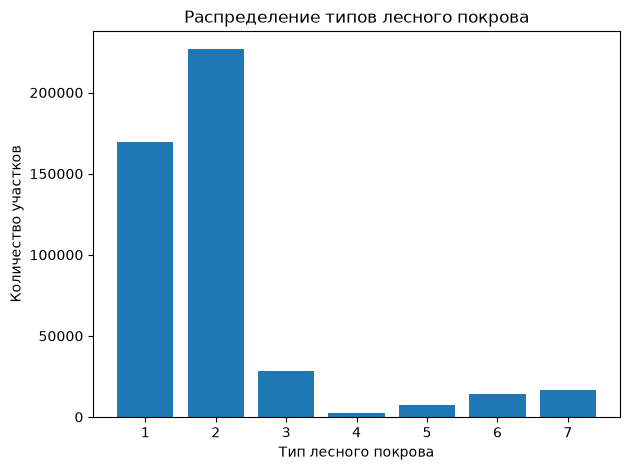

In [6]:
fig, ax = plt.subplots()
ax.bar(values.index.astype(str), values.values)
ax.set_title('Распределение типов лесного покрова')
ax.set_xlabel('Тип лесного покрова')
ax.set_ylabel('Количество участков')
plt.tight_layout()
plt.show()

## Анализ

Как видно по описанию и соответствующему ему барному графику в датасете содрежится 7 классов. Распределение в данном случае сильно не сбалансировано, так как классы 1 и 2, являясь мажоритарными, занимают большую часть всего объема строк, при этом класс 4 вовсе находится в далеко отстающем положении и имеет всего 2198 строк. Ситуация, мягко сказать, плохая. В перспективе модель будет отлично предсказывать 1 и 2 классы и плохо отрабатывать на данных для остальных.

In [7]:
num  = X_train.select_dtypes(include=['float64']).columns.tolist()
cat = X_train.select_dtypes(include=['int64']).columns.tolist()
categorical_idx = [X_train.columns.get_loc(c) for c in cat]

c = y_train.value_counts().sort_index()
tpc = int(c.max() * 0.2)
strat = {cls: min(n, tpc) for cls, n  in c.items()}
strat

{1: 45322, 2: 45322, 3: 28602, 4: 2198, 5: 7594, 6: 13890, 7: 16408}

(317254, 47)


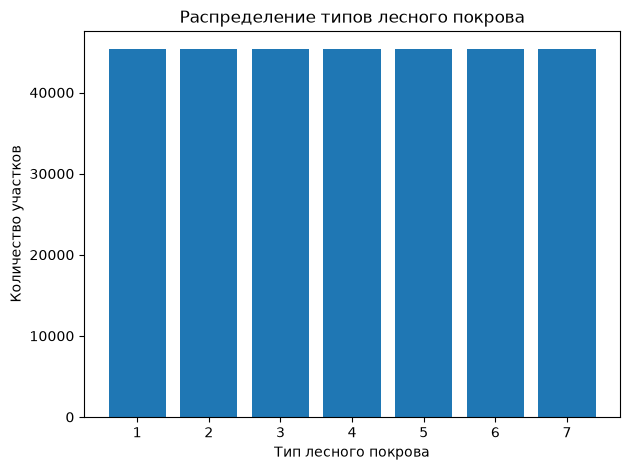

In [8]:
under = RandomUnderSampler(sampling_strategy=strat, random_state=42)
smotenc = SMOTENC(
    categorical_features=categorical_idx,
    sampling_strategy='not majority',
    random_state=42,
    k_neighbors=5,
)

pipe = ImbPipeline([
    ('under', under),
    ('over',  smotenc),
])

X_tr_comb, y_tr_comb = pipe.fit_resample(X_train, y_train)
print(X_tr_comb.shape)

counts = y_tr_comb.value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values)
ax.set_title('Распределение типов лесного покрова')
ax.set_xlabel('Тип лесного покрова')
ax.set_ylabel('Количество участков')
plt.tight_layout()
plt.show()

In [10]:
train_f = pd.concat([X_tr_comb, y_tr_comb], axis=1)
test_f = pd.concat([X_test, y_test], axis=1)
print(f'Train shape: {train_f.shape}')
print(f'Test shape: {test_f.shape}')

Train shape: (317254, 48)
Test shape: (116194, 48)


In [13]:
train_f.to_csv('data/covtype-7-ss.csv', index=False)
test_f.to_csv('data/covtype-7-test-ss.csv', index=False)

## Вывод

В итоге получаем выборку с немного уменьшенной размерностью за счет того, что часть строк мажоритарного класса были удалены. Баланс классов в новой выборке выровнен, однако стоит учесть, что теперь в ней присутствует большое количество синтетических данных из-за того, что миноритарный класс был чересчур малочислен.